# TP SIEVE — Open World Classification

## Classification de logs en monde ouvert avec Peephole LSTM

L'objectif de cette expérimentation est d'évaluer la capacité d'un modèle
Peephole LSTM à classifier des logs appartenant à des classes connues et
à détecter des classes qu'il n'a jamais rencontrées pendant l'entraînement.

Le dataset SIEVE `output_0` contient 30 classes.

L'expérimentation repose sur 6 folds :
- 25 classes connues pour l'entraînement et la validation ;
- 5 classes inconnues réservées à l'évaluation en monde ouvert.

Le modèle est réentraîné indépendamment pour chaque fold.

## Imports et configuration

In [2]:
import re
import time
import copy
import random
import gc

from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import train_test_split

# Reproductibilité
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Choix de l'appareil
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Appareil utilisé :", DEVICE)

# Paramètres
MAX_LEN = 128
MAX_VOCAB = 30000

BATCH_SIZE = 128
EPOCHS = 8

EMBED_DIM = 128
HIDDEN_DIM = 128

LEARNING_RATE = 1e-3

N_FOLDS = 6
N_UNKNOWN = 5

# Dossiers de résultats
RESULTS_DIR = Path("results_open_world")
MODELS_DIR = Path("models_open_world")

RESULTS_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

Appareil utilisé : mps


## Chargement des données

In [3]:
DATA_DIR = Path("processed_data")

TRAIN_FILE = DATA_DIR / "output_0_X_train.csv"
VAL_FILE = DATA_DIR / "output_0_X_val.csv"
TEST_FILE = DATA_DIR / "output_0_X_test.csv"

def standardize(df):

    cols = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    text_col = next(
        (cols[k] for k in ("log", "text", "message") if k in cols),
        None
    )

    label_col = next(
        (cols[k] for k in ("label", "category", "class") if k in cols),
        None
    )

    if text_col is None or label_col is None:
        raise ValueError(
            f"Colonnes texte ou label introuvables : {list(df.columns)}"
        )

    data = df[[text_col, label_col]].copy()
    data.columns = ["text", "label"]

    data["text"] = data["text"].fillna("").astype(str)
    data["label"] = data["label"].astype(str)

    return data


if TRAIN_FILE.exists() and VAL_FILE.exists() and TEST_FILE.exists():

    train_df = standardize(pd.read_csv(TRAIN_FILE))
    val_df = standardize(pd.read_csv(VAL_FILE))
    test_df = standardize(pd.read_csv(TEST_FILE))

    print("Partitions existantes chargées.")

else:
    raise FileNotFoundError(
        "Les trois fichiers CSV sont introuvables dans processed_data/."
    )


print("Taille du train :", len(train_df))
print("Taille de la validation :", len(val_df))
print("Taille du test :", len(test_df))

print("Nombre de classes :", train_df["label"].nunique())

display(train_df.head())

Partitions existantes chargées.
Taille du train : 24500
Taille de la validation : 5250
Taille du test : 5250
Nombre de classes : 30


,text,label
0,Feb 01 06:51:54 email-88.williams-green.net br...,6
1,2004-02-20T05:52:31 INFO 6349 --- [ ...,24
2,"173.152.126.189 ""DELETE /general/commercial/mi...",16
3,310590 08:58:53 [Note] /%mercedesallen/skin/ma...,23
4,"186.116.244.234 ""DELETE /job/whom/know/he/once...",16


## Vérification de la répartition des classes

In [4]:
classes = sorted(train_df["label"].unique())

print("Nombre de classes :", len(classes))

print("\nListe des classes :")

for i, label in enumerate(classes):
    print(i + 1, "-", label)

# Vérification des classes dans les partitions
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    missing = set(classes) - set(df["label"].unique())

    print(
        f"{name} : {df['label'].nunique()} classes | "
        f"Classes manquantes : {len(missing)}"
    )

assert len(classes) == 30, (
    f"Le TP attend 30 classes, mais {len(classes)} ont été trouvées."
)

Nombre de classes : 30

Liste des classes :
1 - 0
2 - 1
3 - 10
4 - 11
5 - 12
6 - 13
7 - 14
8 - 15
9 - 16
10 - 17
11 - 18
12 - 19
13 - 2
14 - 20
15 - 21
16 - 22
17 - 23
18 - 24
19 - 25
20 - 26
21 - 27
22 - 28
23 - 29
24 - 3
25 - 4
26 - 5
27 - 6
28 - 7
29 - 8
30 - 9
Train : 30 classes | Classes manquantes : 0
Validation : 30 classes | Classes manquantes : 0
Test : 30 classes | Classes manquantes : 0


## Visualisation de la distribution des classes

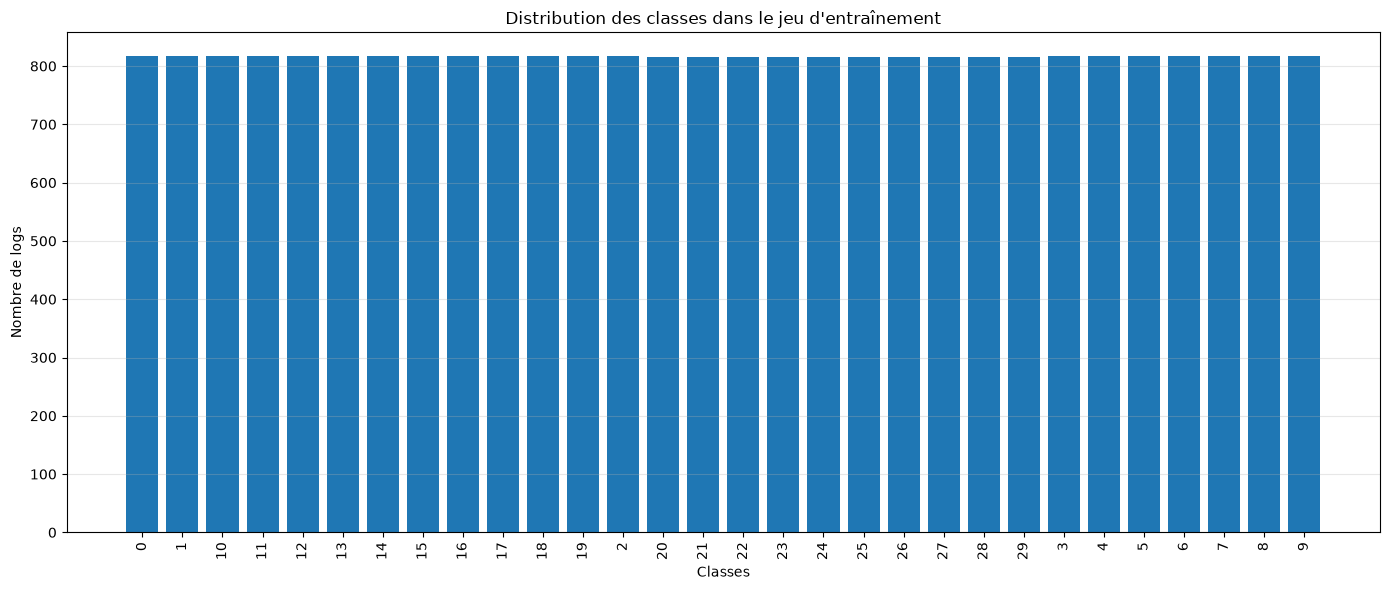

In [5]:
class_counts = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(14, 6))

plt.bar(class_counts.index, class_counts.values)

plt.title("Distribution des classes dans le jeu d'entraînement")
plt.xlabel("Classes")
plt.ylabel("Nombre de logs")

plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Construction des six folds - Création des groupes de classes

In [6]:
folds = []

for i in range(N_FOLDS):

    start = i * N_UNKNOWN
    end = start + N_UNKNOWN

    unknown_classes = classes[start:end]

    known_classes = [
        c for c in classes
        if c not in unknown_classes
    ]

    folds.append({
        "fold": i + 1,
        "known": known_classes,
        "unknown": unknown_classes
    })


for fold in folds:

    print(f"\nFOLD {fold['fold']}")

    print("Classes inconnues :")
    print(fold["unknown"])

    print("\nNombre de classes connues :", len(fold["known"]))


FOLD 1
Classes inconnues :
['0', '1', '10', '11', '12']

Nombre de classes connues : 25

FOLD 2
Classes inconnues :
['13', '14', '15', '16', '17']

Nombre de classes connues : 25

FOLD 3
Classes inconnues :
['18', '19', '2', '20', '21']

Nombre de classes connues : 25

FOLD 4
Classes inconnues :
['22', '23', '24', '25', '26']

Nombre de classes connues : 25

FOLD 5
Classes inconnues :
['27', '28', '29', '3', '4']

Nombre de classes connues : 25

FOLD 6
Classes inconnues :
['5', '6', '7', '8', '9']

Nombre de classes connues : 25


## Prétraitement des textes — Tokenisation

In [8]:
TOKEN_RE = re.compile(
    r"[A-Za-z0-9_./:@=-]+|[^\w\s]",
    re.UNICODE
)

def tokenize(text):
    return TOKEN_RE.findall(str(text).lower())

## Création du vocabulaire

In [9]:
def build_vocabulary(train_data):

    counts = Counter()

    for text in train_data["text"]:
        counts.update(tokenize(text))

    itos = ["<PAD>", "<UNK>"]

    itos += [
        word
        for word, _ in counts.most_common(MAX_VOCAB - 2)
    ]

    stoi = {
        word: index
        for index, word in enumerate(itos)
    }

    return stoi, itos


PAD = 0
UNK = 1


def encode_text(text, stoi):

    tokens = tokenize(text)[:MAX_LEN]

    ids = [
        stoi.get(token, UNK)
        for token in tokens
    ]

    if len(ids) == 0:
        ids = [UNK]

    ids += [PAD] * (MAX_LEN - len(ids))

    return ids

## Dataset PyTorch

In [10]:
class LogDataset(Dataset):

    def __init__(self, dataframe, stoi):

        self.texts = dataframe["text"].tolist()
        self.labels = dataframe["y"].astype(int).tolist()

        self.stoi = stoi

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        x = encode_text(
            self.texts[index],
            self.stoi
        )

        y = self.labels[index]

        return (
            torch.tensor(x, dtype=torch.long),
            torch.tensor(y, dtype=torch.long)
        )

## Architecture Peephole LSTM — Définition de la cellule Peephole LSTM

In [11]:
class PeepholeCell(nn.Module):

    def __init__(self, input_dim, hidden_dim):

        super().__init__()

        self.xg = nn.Linear(input_dim, 4 * hidden_dim)

        self.hg = nn.Linear(
            hidden_dim,
            4 * hidden_dim,
            bias=False
        )

        self.pi = nn.Parameter(torch.zeros(hidden_dim))
        self.pf = nn.Parameter(torch.zeros(hidden_dim))
        self.po = nn.Parameter(torch.zeros(hidden_dim))


    def forward(self, x, state):

        h, c = state

        i, f, g, o = (
            self.xg(x) + self.hg(h)
        ).chunk(4, dim=-1)

        i = torch.sigmoid(i + self.pi * c)
        f = torch.sigmoid(f + self.pf * c)

        g = torch.tanh(g)

        cn = f * c + i * g

        o = torch.sigmoid(o + self.po * cn)

        hn = o * torch.tanh(cn)

        return hn, cn

## Classifieur Peephole LSTM

In [12]:
class PeepholeClassifier(nn.Module):

    def __init__(self, vocab_size, num_classes):

        super().__init__()

        self.emb = nn.Embedding(
            vocab_size,
            EMBED_DIM,
            padding_idx=PAD
        )

        self.cell = PeepholeCell(
            EMBED_DIM,
            HIDDEN_DIM
        )

        self.drop = nn.Dropout(0.3)

        self.fc = nn.Linear(
            HIDDEN_DIM,
            num_classes
        )


    def forward(self, x):

        z = self.emb(x)

        batch_size = x.size(0)

        h = torch.zeros(
            batch_size,
            HIDDEN_DIM,
            device=x.device
        )

        c = torch.zeros_like(h)

        for t in range(z.size(1)):

            hn, cn = self.cell(
                z[:, t],
                (h, c)
            )

            active = (
                x[:, t] != PAD
            ).unsqueeze(1)

            h = torch.where(active, hn, h)
            c = torch.where(active, cn, c)

        return self.fc(self.drop(h))

## Entraînement et évaluation — Fonctions d'entraînement et de prédiction

In [13]:
def calculate_metrics(y_true, y_pred):

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "macro_f1": f1
    }


def train_model(model, train_loader, val_loader):

    model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    best_f1 = -1
    best_state = None

    history = []

    start_time = time.time()

    for epoch in range(1, EPOCHS + 1):

        model.train()

        total_loss = 0

        for x, y in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad()

            logits = model(x)

            loss = criterion(logits, y)

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                1.0
            )

            optimizer.step()

            total_loss += loss.item()

        # Évaluation sur validation
        model.eval()

        val_true = []
        val_pred = []

        with torch.no_grad():

            for x, y in val_loader:

                x = x.to(DEVICE)

                logits = model(x)

                predictions = logits.argmax(dim=1)

                val_true.extend(y.numpy())
                val_pred.extend(predictions.cpu().numpy())

        val_metrics = calculate_metrics(
            val_true,
            val_pred
        )

        avg_loss = total_loss / max(1, len(train_loader))

        history.append({
            "epoch": epoch,
            "train_loss": avg_loss,
            **val_metrics
        })

        print(
            f"Epoch {epoch}/{EPOCHS} | "
            f"Loss : {avg_loss:.4f} | "
            f"Validation Macro-F1 : {val_metrics['macro_f1']:.4f}"
        )

        if val_metrics["macro_f1"] > best_f1:

            best_f1 = val_metrics["macro_f1"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    if best_state is not None:
        model.load_state_dict(best_state)

    elapsed = time.time() - start_time

    return model, elapsed, pd.DataFrame(history)


@torch.no_grad()
def predict_model(model, loader):

    model.eval()

    all_labels = []
    all_probabilities = []

    for x, y in loader:

        x = x.to(DEVICE)

        logits = model(x)

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        all_labels.extend(y.numpy())

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

    return (
        np.array(all_labels),
        np.array(all_probabilities)
    )

## Fonction de préparation d'un fold

In [14]:
def prepare_fold(fold):

    known_classes = fold["known"]
    unknown_classes = fold["unknown"]

    # On conserve uniquement les classes connues
    train_known = train_df[
        train_df["label"].isin(known_classes)
    ].copy()

    val_known = val_df[
        val_df["label"].isin(known_classes)
    ].copy()

    test_known = test_df[
        test_df["label"].isin(known_classes)
    ].copy()

    # Classes inconnues : uniquement dans le test ouvert
    test_unknown = test_df[
        test_df["label"].isin(unknown_classes)
    ].copy()

    # Encodage local des 25 classes connues
    label_to_id = {
        label: index
        for index, label in enumerate(known_classes)
    }

    train_known["y"] = train_known["label"].map(label_to_id)
    val_known["y"] = val_known["label"].map(label_to_id)
    test_known["y"] = test_known["label"].map(label_to_id)

    # Les inconnues ne reçoivent aucune classe connue.
    # -1 sert uniquement à les identifier lors de l'évaluation.
    test_unknown["y"] = -1

    print(f"\nFold {fold['fold']}")

    print("Train :", len(train_known))
    print("Validation :", len(val_known))
    print("Test connu :", len(test_known))
    print("Test inconnu :", len(test_unknown))

    return (
        train_known,
        val_known,
        test_known,
        test_unknown,
        label_to_id
    )

## Fonction de création des DataLoaders

In [15]:
def create_loaders(
    train_data,
    val_data,
    test_known,
    test_unknown
):

    # Vocabulaire construit uniquement sur le train connu
    stoi, itos = build_vocabulary(train_data)

    train_loader = DataLoader(
        LogDataset(train_data, stoi),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        LogDataset(val_data, stoi),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_known_loader = DataLoader(
        LogDataset(test_known, stoi),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_unknown_loader = DataLoader(
        LogDataset(test_unknown, stoi),
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    return (
        stoi,
        itos,
        train_loader,
        val_loader,
        test_known_loader,
        test_unknown_loader
    )

## Détection des classes inconnues

Le modèle produit une probabilité pour chacune des 25 classes connues.

La classe ayant la probabilité la plus élevée est retenue comme prédiction.

Cependant, en monde ouvert, le modèle doit pouvoir rejeter une prédiction
lorsque sa confiance est insuffisante.

Nous utilisons donc un seuil de confiance calculé à partir des prédictions
sur les données de validation connues.

Les exemples dont la confiance maximale est inférieure à ce seuil sont
considérés comme inconnus.

## Calcul du seuil de confiance

In [16]:
def calculate_threshold(model, val_loader):

    model.eval()

    confidences = []

    with torch.no_grad():

        for x, y in val_loader:

            x = x.to(DEVICE)

            logits = model(x)

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            max_confidence = probabilities.max(
                dim=1
            ).values

            confidences.extend(
                max_confidence.cpu().numpy()
            )

    threshold = np.quantile(
        confidences,
        0.05
    )

    return float(threshold)

## Exécution des six folds — Boucle principale des six folds

In [17]:
fold_results = []
fold_histories = []

all_fold_predictions = {}

for fold in folds:

    print("\n" + "=" * 60)
    print(f" DÉBUT DU FOLD {fold['fold']}")
    print("=" * 60)

    # Reproductibilité pour chaque fold
    fold_seed = SEED + fold["fold"]

    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(fold_seed)

    # 1. Préparation des données
    (
        train_known,
        val_known,
        test_known,
        test_unknown,
        label_to_id
    ) = prepare_fold(fold)

    # 2. Création des DataLoaders
    (
        stoi,
        itos,
        train_loader,
        val_loader,
        test_known_loader,
        test_unknown_loader
    ) = create_loaders(
        train_known,
        val_known,
        test_known,
        test_unknown
    )

    # 3. Création du modèle
    model = PeepholeClassifier(
        vocab_size=len(itos),
        num_classes=len(fold["known"])
    )

    # 4. Entraînement
    model, elapsed, history = train_model(
        model,
        train_loader,
        val_loader
    )

    history["fold"] = fold["fold"]
    fold_histories.append(history)

    # 5. Sauvegarde du modèle
    model_path = MODELS_DIR / f"peephole_fold_{fold['fold']}.pt"

    torch.save(
        model.state_dict(),
        model_path
    )

    # 6. Calcul du seuil sur la validation connue
    threshold = calculate_threshold(
        model,
        val_loader
    )

    # 7. Prédictions sur le test connu
    y_known, prob_known = predict_model(
        model,
        test_known_loader
    )

    # 8. Prédictions sur le test inconnu
    y_unknown, prob_unknown = predict_model(
        model,
        test_unknown_loader
    )

    # 9. Prédictions en monde fermé
    pred_known = prob_known.argmax(axis=1)

    closed_metrics = calculate_metrics(
        y_known,
        pred_known
    )

    # 10. Confiance maximale
    confidence_known = prob_known.max(axis=1)
    confidence_unknown = prob_unknown.max(axis=1)

    # 11. Détection connu / inconnu
    # 1 = connu ; 0 = inconnu

    true_binary = np.concatenate([
        np.ones(len(y_known)),
        np.zeros(len(y_unknown))
    ])

    pred_binary = np.concatenate([
        (confidence_known >= threshold).astype(int),
        (confidence_unknown < threshold).astype(int)
    ])

    binary_accuracy = accuracy_score(
        true_binary,
        pred_binary
    )

    binary_precision = precision_score(
        true_binary,
        pred_binary,
        zero_division=0
    )

    binary_recall = recall_score(
        true_binary,
        pred_binary,
        zero_division=0
    )

    binary_f1 = f1_score(
        true_binary,
        pred_binary,
        zero_division=0
    )

    # 12. Taux de rejet des inconnues
    unknown_rejection_rate = np.mean(
        confidence_unknown < threshold
    )

    # 13. Taux d'acceptation des classes connues
    known_acceptance_rate = np.mean(
        confidence_known >= threshold
    )

    # 14. Enregistrement des résultats
    result = {
        "fold": fold["fold"],
        "closed_accuracy": closed_metrics["accuracy"],
        "closed_macro_f1": closed_metrics["macro_f1"],
        "threshold": threshold,
        "binary_accuracy": binary_accuracy,
        "binary_precision": binary_precision,
        "binary_recall": binary_recall,
        "binary_f1": binary_f1,
        "unknown_rejection_rate": unknown_rejection_rate,
        "known_acceptance_rate": known_acceptance_rate,
        "training_time_sec": elapsed
    }

    fold_results.append(result)

    all_fold_predictions[fold["fold"]] = {
        "y_known": y_known,
        "pred_known": pred_known,
        "confidence_known": confidence_known,
        "confidence_unknown": confidence_unknown,
        "threshold": threshold,
        "true_binary": true_binary,
        "pred_binary": pred_binary
    }

    print("\nRésultats du fold :", result)

    # Libération de la mémoire
    del model
    gc.collect()

    if DEVICE.type == "mps":
        torch.mps.empty_cache()


print("\nTous les folds sont terminés.")


 DÉBUT DU FOLD 1

Fold 1
Train : 20415
Validation : 4375
Test connu : 4375
Test inconnu : 875
Epoch 1/8 | Loss : 1.1904 | Validation Macro-F1 : 0.9793
Epoch 2/8 | Loss : 0.0815 | Validation Macro-F1 : 0.9913
Epoch 3/8 | Loss : 0.0260 | Validation Macro-F1 : 0.9915
Epoch 4/8 | Loss : 0.0188 | Validation Macro-F1 : 0.9929
Epoch 5/8 | Loss : 0.0113 | Validation Macro-F1 : 0.9925
Epoch 6/8 | Loss : 0.0082 | Validation Macro-F1 : 0.9895
Epoch 7/8 | Loss : 0.0051 | Validation Macro-F1 : 0.9911
Epoch 8/8 | Loss : 0.0041 | Validation Macro-F1 : 0.9911

Résultats du fold : {'fold': 1, 'closed_accuracy': 0.9926857142857143, 'closed_macro_f1': 0.9926737515301827, 'threshold': 0.9837536811828613, 'binary_accuracy': 0.8377142857142857, 'binary_precision': 0.8644734119594455, 'binary_recall': 0.9549714285714286, 'binary_f1': 0.9074717636837533, 'unknown_rejection_rate': np.float64(0.7485714285714286), 'known_acceptance_rate': np.float64(0.9549714285714286), 'training_time_sec': 144.30012202262878}


## Analyse des résultats — Tableau récapitulatif des six folds

In [18]:
results_df = pd.DataFrame(fold_results)

display(
    results_df.round(4)
)

results_df.to_csv(
    RESULTS_DIR / "open_world_results.csv",
    index=False
)

,fold,closed_accuracy,closed_macro_f1,threshold,binary_accuracy,binary_precision,binary_recall,binary_f1,unknown_rejection_rate,known_acceptance_rate,training_time_sec
0,1,0.9927,0.9927,0.9838,0.8377,0.8645,0.9550,0.9075,0.7486,0.9550,144.3001
1,2,0.9719,0.9716,0.7096,0.8823,0.8989,0.9675,0.9320,0.5440,0.9675,141.2631
2,3,0.9769,0.9767,0.6985,0.8964,0.9161,0.9639,0.9394,0.4411,0.9639,142.3677
3,4,0.9719,0.9716,0.6313,0.8773,0.8975,0.9627,0.9290,0.5497,0.9627,142.2282
4,5,0.9799,0.9796,0.7886,0.9356,0.9481,0.9762,0.9619,0.2674,0.9762,143.4163
5,6,0.9906,0.9906,0.9870,0.8126,0.8452,0.9488,0.8940,0.8686,0.9488,141.7920


## Moyenne et écart-type des performances

In [19]:
metrics_columns = [
    "closed_accuracy",
    "closed_macro_f1",
    "binary_accuracy",
    "binary_precision",
    "binary_recall",
    "binary_f1",
    "unknown_rejection_rate",
    "known_acceptance_rate"
]

summary = results_df[metrics_columns].agg(
    ["mean", "std"]
)

display(summary.round(4))

summary.to_csv(
    RESULTS_DIR / "open_world_summary.csv"
)

,closed_accuracy,closed_macro_f1,binary_accuracy,binary_precision,binary_recall,binary_f1,unknown_rejection_rate,known_acceptance_rate
mean,0.9806,0.9805,0.8737,0.8951,0.9624,0.9273,0.5699,0.9624
std,0.0091,0.0092,0.0435,0.0366,0.0096,0.0240,0.2146,0.0096


## Évolution des performances selon les folds

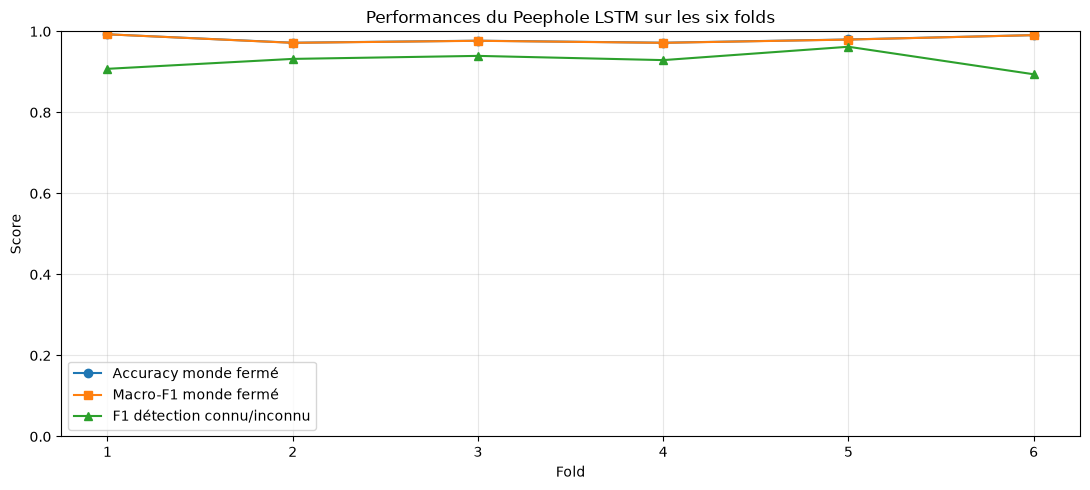

In [20]:
plt.figure(figsize=(11, 5))

plt.plot(
    results_df["fold"],
    results_df["closed_accuracy"],
    marker="o",
    label="Accuracy monde fermé"
)

plt.plot(
    results_df["fold"],
    results_df["closed_macro_f1"],
    marker="s",
    label="Macro-F1 monde fermé"
)

plt.plot(
    results_df["fold"],
    results_df["binary_f1"],
    marker="^",
    label="F1 détection connu/inconnu"
)

plt.xlabel("Fold")
plt.ylabel("Score")
plt.title("Performances du Peephole LSTM sur les six folds")

plt.xticks(range(1, 7))
plt.ylim(0, 1)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## Taux de rejet des classes inconnues

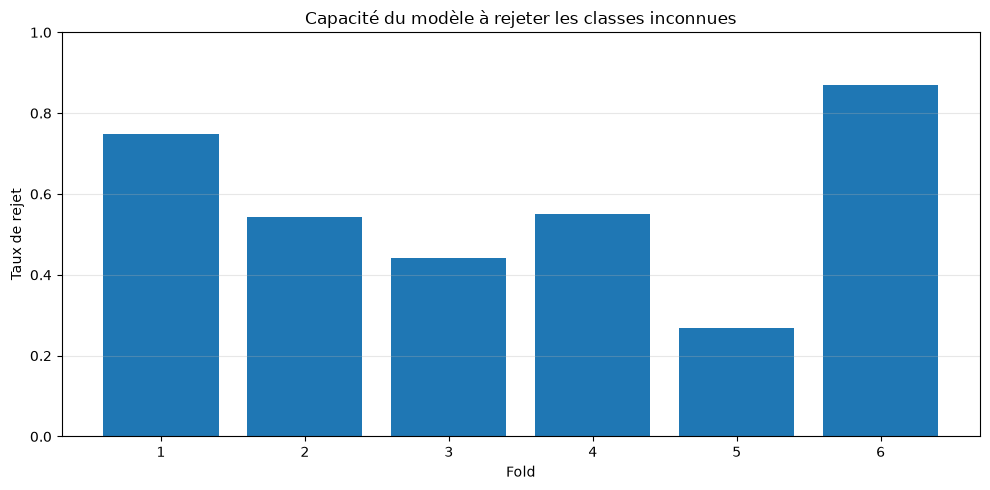

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["fold"],
    results_df["unknown_rejection_rate"]
)

plt.xlabel("Fold")
plt.ylabel("Taux de rejet")

plt.title(
    "Capacité du modèle à rejeter les classes inconnues"
)

plt.xticks(range(1, 7))
plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Matrice de confusion : connu / inconnu

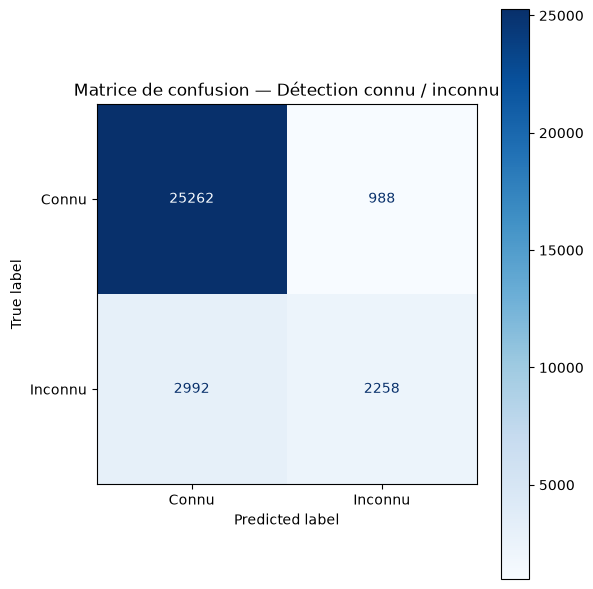

In [22]:
all_true = []
all_pred = []

for fold_id, data in all_fold_predictions.items():

    all_true.extend(data["true_binary"])
    all_pred.extend(data["pred_binary"])


cm = confusion_matrix(
    all_true,
    all_pred,
    labels=[1, 0]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Connu", "Inconnu"]
)

fig, ax = plt.subplots(figsize=(6, 6))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Matrice de confusion — Détection connu / inconnu"
)

plt.tight_layout()
plt.show()

## Matrice de confusion des classes connues

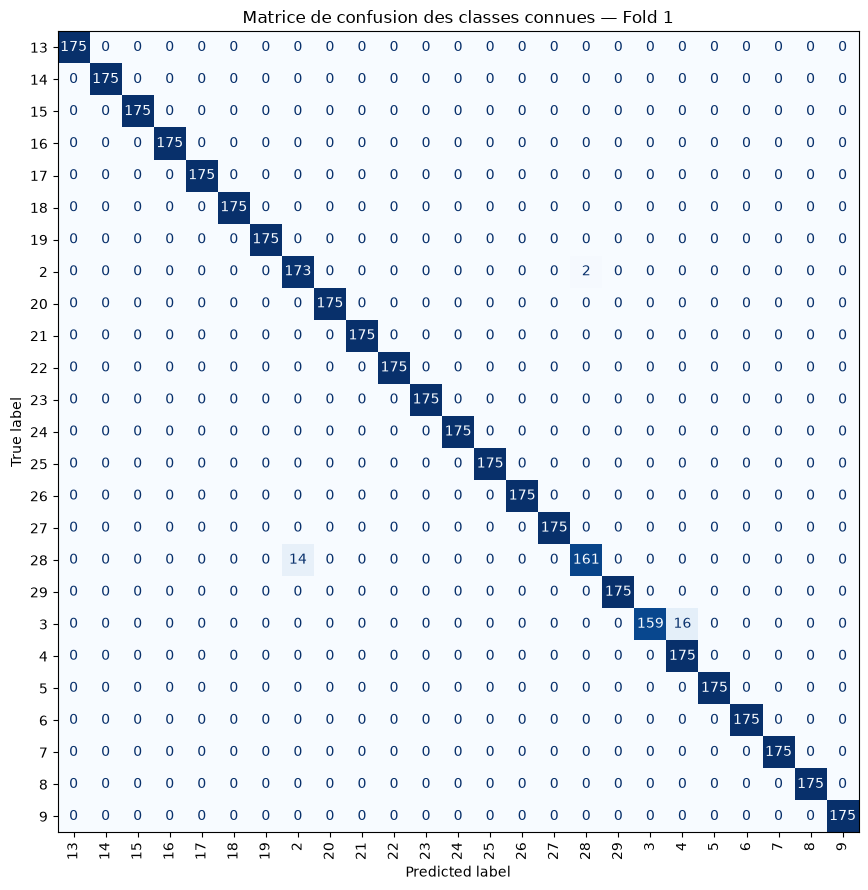

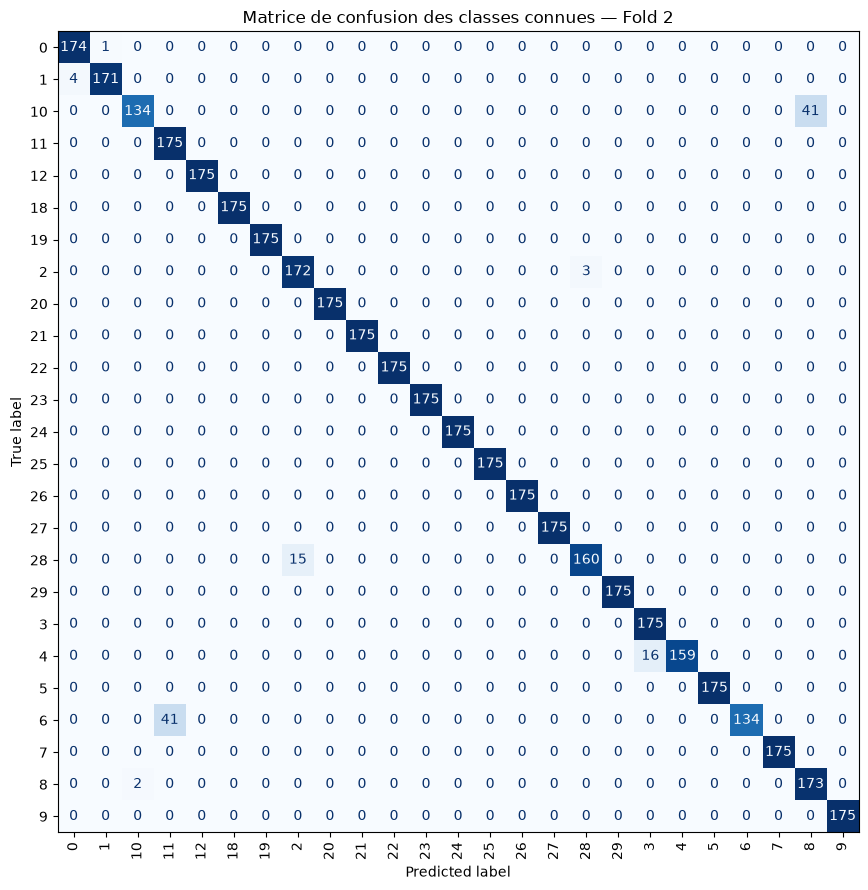

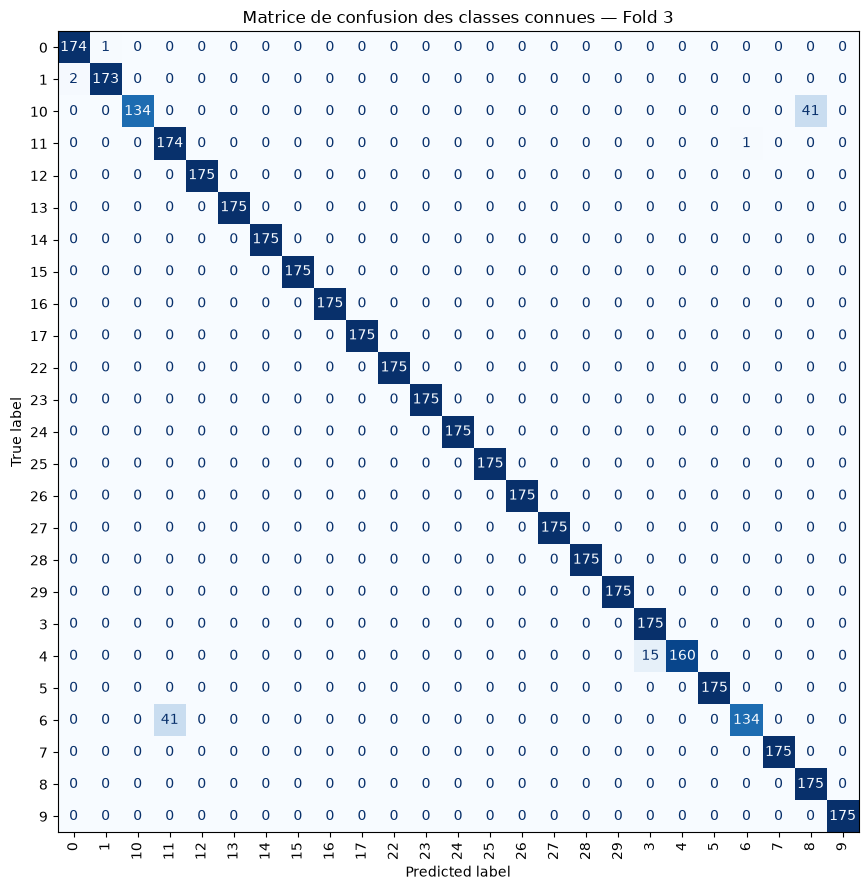

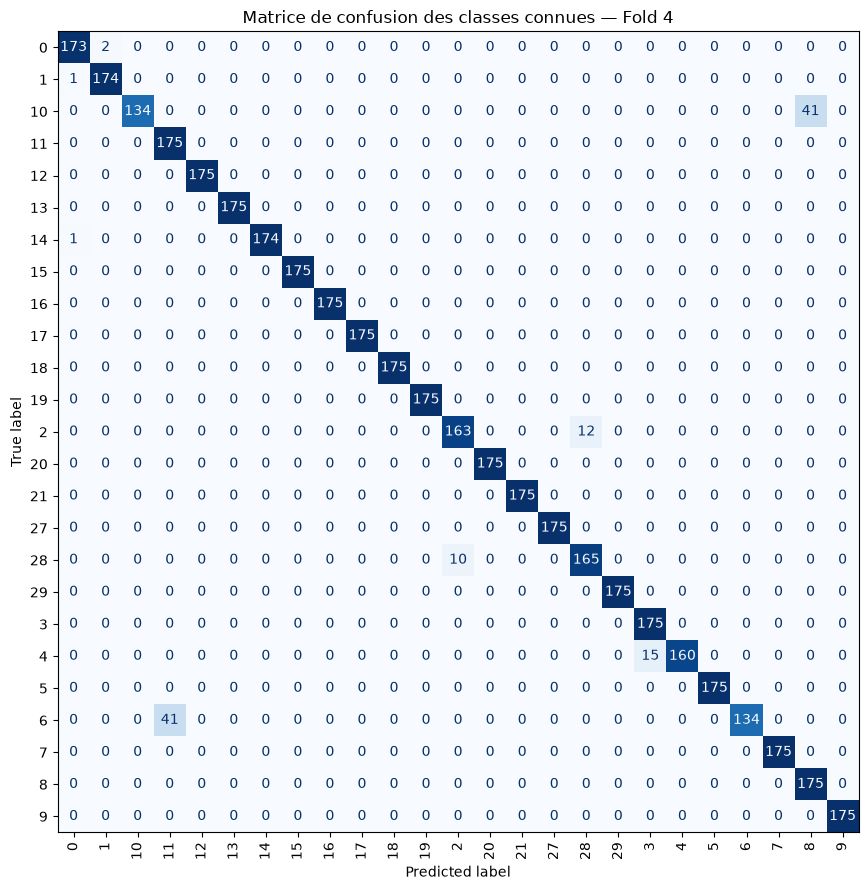

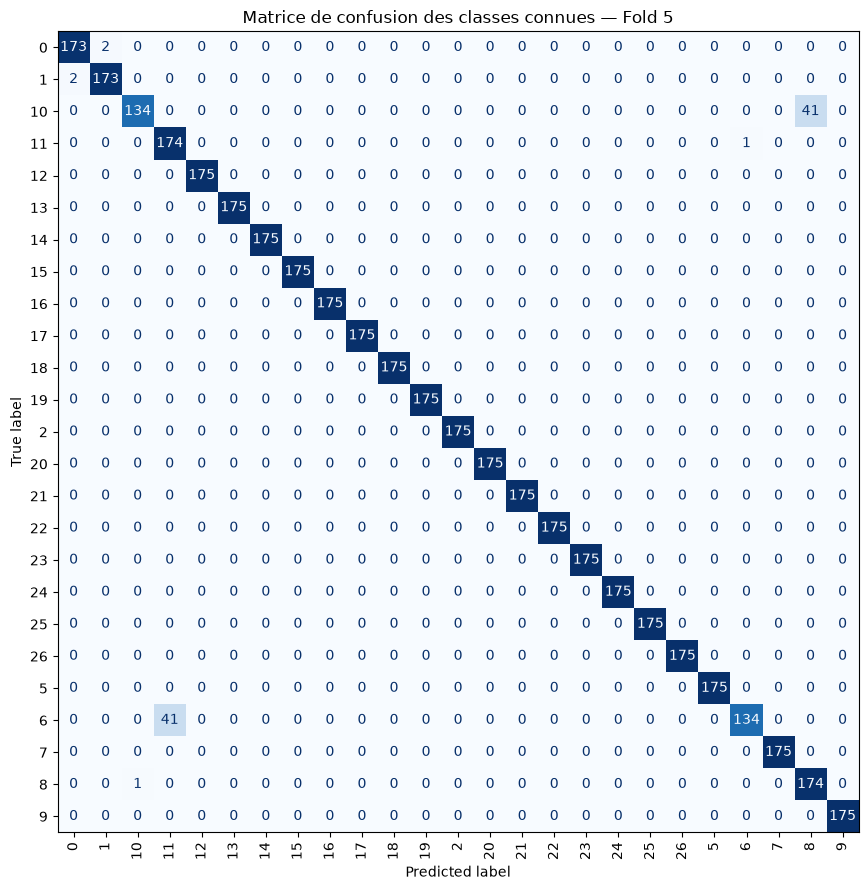

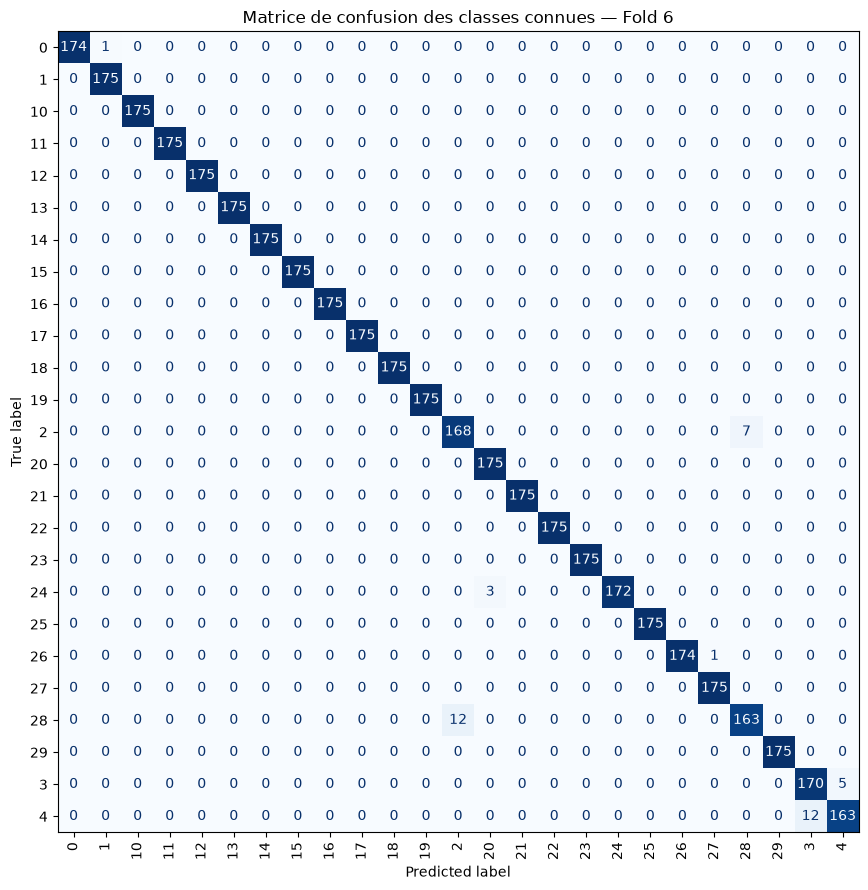

In [23]:
for fold in folds:

    fold_id = fold["fold"]

    data = all_fold_predictions[fold_id]

    cm = confusion_matrix(
        data["y_known"],
        data["pred_known"],
        labels=list(range(25))
    )

    fig, ax = plt.subplots(figsize=(10, 9))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=fold["known"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=90,
        colorbar=False
    )

    ax.set_title(
        f"Matrice de confusion des classes connues — Fold {fold_id}"
    )

    plt.tight_layout()
    plt.show()

## Comparaison des confiances

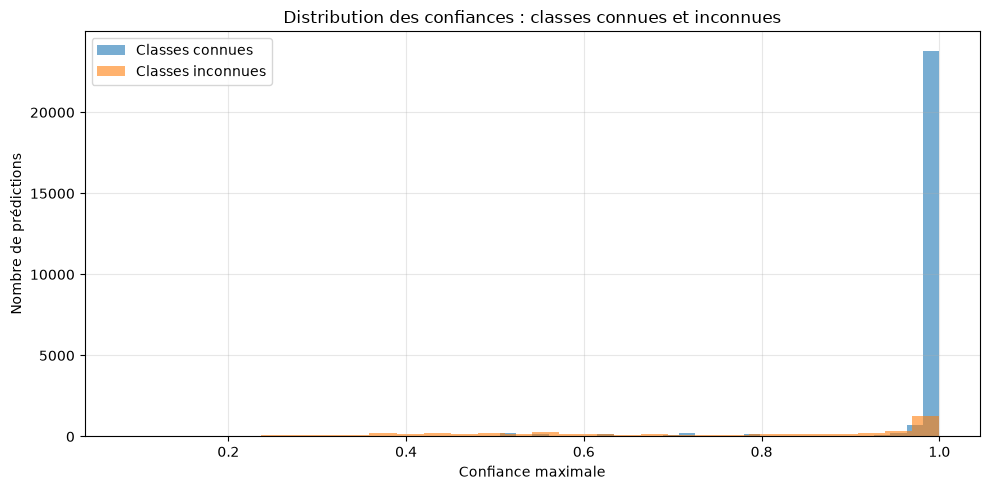

In [24]:
known_confidences = []
unknown_confidences = []

for fold_id, data in all_fold_predictions.items():

    known_confidences.extend(
        data["confidence_known"]
    )

    unknown_confidences.extend(
        data["confidence_unknown"]
    )


plt.figure(figsize=(10, 5))

plt.hist(
    known_confidences,
    bins=30,
    alpha=0.6,
    label="Classes connues"
)

plt.hist(
    unknown_confidences,
    bins=30,
    alpha=0.6,
    label="Classes inconnues"
)

plt.xlabel("Confiance maximale")
plt.ylabel("Nombre de prédictions")

plt.title(
    "Distribution des confiances : classes connues et inconnues"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Courbes d'apprentissage

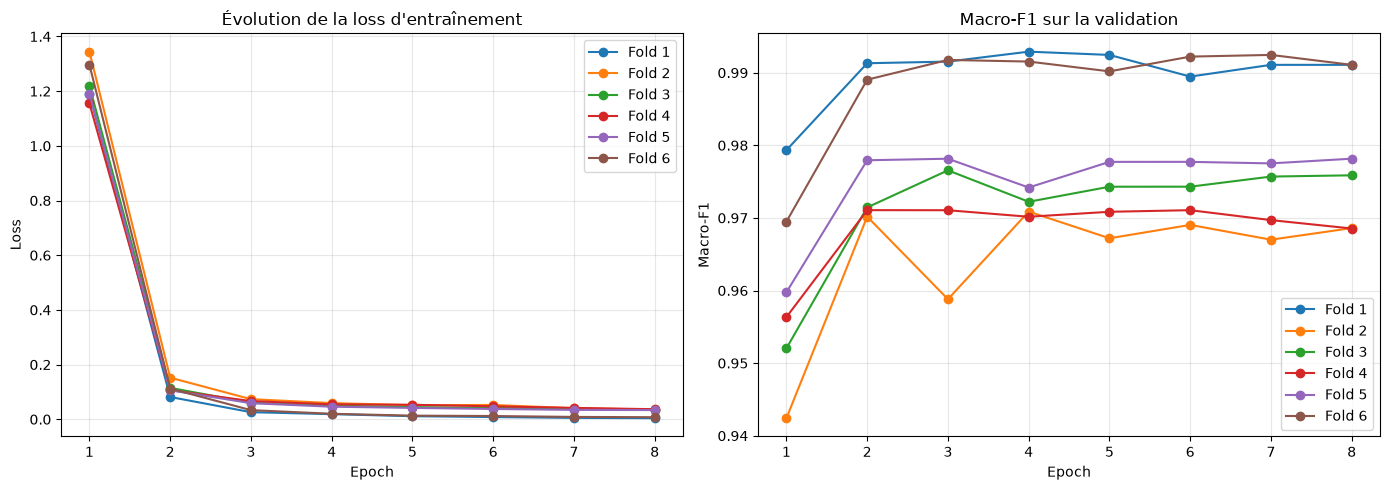

In [25]:
history_df = pd.concat(
    fold_histories,
    ignore_index=True
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for fold_id in range(1, 7):

    data = history_df[
        history_df["fold"] == fold_id
    ]

    axes[0].plot(
        data["epoch"],
        data["train_loss"],
        marker="o",
        label=f"Fold {fold_id}"
    )

    axes[1].plot(
        data["epoch"],
        data["macro_f1"],
        marker="o",
        label=f"Fold {fold_id}"
    )


axes[0].set_title("Évolution de la loss d'entraînement")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Macro-F1 sur la validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].grid(alpha=0.3)

axes[0].legend()
axes[1].legend()

plt.tight_layout()
plt.show()

## Conclusion expérimentale — Génération d'un résumé automatique

In [26]:
print("=" * 60)
print("RÉSUMÉ DE L'EXPÉRIMENTATION OPEN WORLD")
print("=" * 60)

print("\nNombre de folds :", len(results_df))

print(
    "\nAccuracy moyenne en monde fermé :",
    round(results_df["closed_accuracy"].mean(), 4)
)

print(
    "Macro-F1 moyen en monde fermé :",
    round(results_df["closed_macro_f1"].mean(), 4)
)

print(
    "\nAccuracy moyenne de détection :",
    round(results_df["binary_accuracy"].mean(), 4)
)

print(
    "F1 moyen de détection :",
    round(results_df["binary_f1"].mean(), 4)
)

print(
    "\nTaux moyen de rejet des inconnues :",
    round(results_df["unknown_rejection_rate"].mean(), 4)
)

print(
    "Taux moyen d'acceptation des connues :",
    round(results_df["known_acceptance_rate"].mean(), 4)
)

print(
    "\nTemps moyen d'entraînement par fold :",
    round(results_df["training_time_sec"].mean(), 2),
    "secondes"
)

print("\n" + "=" * 60)

RÉSUMÉ DE L'EXPÉRIMENTATION OPEN WORLD

Nombre de folds : 6

Accuracy moyenne en monde fermé : 0.9806
Macro-F1 moyen en monde fermé : 0.9805

Accuracy moyenne de détection : 0.8737
F1 moyen de détection : 0.9273

Taux moyen de rejet des inconnues : 0.5699
Taux moyen d'acceptation des connues : 0.9624

Temps moyen d'entraînement par fold : 142.56 secondes

